# Predict opening event percent returns with linear regression

**Target:** raw opening-strategy event profit / pre-event bankroll * 100, including moneylines and parlays, using the opening inference model and saved no-decay strategy. Keep all events: trend categories are predictors, not filters. No additional stake scaling.

**Predictors (all known before the target event):**

| Variable | Definition |
|---|---|
| At/above five-year advantage mean | Indicator that the previous event-end 100-fight rolling Vegas-minus-model Brier advantage is **>=** the mean of event-end rolling advantage observations in `[target date - 5 calendar years, target date)`. Equal weight per historical event. |
| Trend: down / flat / up | 5-event EWMA of event-end 100-fight advantage, followed by a 5-point slope normalized by original-training-period SD of the smoothed series; flat is inclusive **+/-0.02**. Shift to the following event. Downtrend is the regression reference category. |
| Prior Brier score | Previous event's unsmoothed equal-fight average **actual opening Vegas Brier**. |
| Prior actual minus expected Brier | Previous event's mean of `(p-y)^2 - p*(1-p)`, with opening no-vig Vegas probability p. This is a previous single-event measure, not a 100-fight average. |
| Brier event-average autocorrelation | Lag-1 normalized ACF of unsmoothed actual opening Vegas Brier event averages over the **128 previous events**. Demean within the historical window, without detrending; `sum(z[1:]*z[:-1])/sum(z*z)`. |

Historical warmup uses the matching prediction model for each strategy split. The test base prediction model was refitted on train+validation, so its Brier-advantage features can change at that boundary. Regression coefficient fitting and continuous-feature scaling use validation only for the main test evaluation.

This is exploratory: these periods have already been inspected, saved strategy parameters were selected previously, and warmup includes fitted probabilities. Chronological evaluation prevents this return regression from fitting test outcomes; it does not make the whole research process an untouched prospective test.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/ufc_betting').is_dir())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from ufc_betting.config import settings
FLAT_BAND = .02
ACF_HISTORY_EVENTS = 128
HAC_LAGS = 5


## Load matching histories and verify event returns

Reconstruct the same source histories and fight ordering as `rolling_brier.ipynb`. Check saved probabilities against prediction exports and verify sequential bankroll accounting within each split. This notebook runs independently; it does not execute another notebook.


In [2]:
# Self-contained analysis: no dependence on later notebook cells.
from scipy.stats import pearsonr, spearmanr
MEAN_ADV_WINDOW = 100
mean_adv_root = settings.data_dir / 'model_comparisons/lr_open_close/report_predictions'
mean_adv_backtests = settings.data_dir / 'backtest_results/model_comparisons/inference_market_models'
mean_adv_keys = ['date','fighter_red','fighter_blue']

def mean_adv_score(frame):
    frame = frame.copy()
    frame['date'] = pd.to_datetime(frame.date).dt.normalize()
    model = pd.to_numeric(frame.proba_red,errors='coerce')
    red = pd.to_numeric(frame.dec_open_red,errors='coerce')
    blue = pd.to_numeric(frame.dec_open_blue,errors='coerce')
    good = frame.winner.isin([0,1]) & model.between(0,1) & np.isfinite(red) & np.isfinite(blue) & red.gt(1) & blue.gt(1)
    vegas = (1/red)/(1/red+1/blue)
    frame = frame.loc[good].copy()
    frame['advantage'] = ((vegas-frame.winner)**2-(model-frame.winner)**2).loc[good]
    frame['model_correct'] = (model.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    frame['vegas_correct'] = (vegas.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    return frame.sort_values('date',kind='stable').reset_index(drop=True)

mean_adv_train = mean_adv_score(pd.read_csv(mean_adv_root/'train/open/inference/train_with_open.csv'))
mean_adv_train['rolling_advantage'] = mean_adv_train.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
mean_adv_training_mean = mean_adv_train.rolling_advantage.mean()
mean_adv_training_end = mean_adv_train.date.max()
mean_adv_train_endpoints = mean_adv_train.groupby('date').rolling_advantage.last()
mean_adv_train['prior_event_advantage'] = mean_adv_train.date.map(mean_adv_train_endpoints.shift(1))
mean_adv_return_pairs={};mean_adv_corr_rows=[];mean_adv_histories={}
for split,fit,prefix,prediction_split in [('Validation','train','train_val','val'),('Test','trainval','trainval_test','test')]:
    base=mean_adv_root/fit/'open/inference'
    warm=mean_adv_score(pd.read_csv(base/'train_with_open.csv'))
    prediction=pd.read_csv(base/f'{prediction_split}_with_open.csv',parse_dates=['date'])
    saved=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
    for frame in [prediction,saved]:frame['date']=frame.date.dt.normalize()
    matched=saved.merge(prediction[mean_adv_keys+['proba_red','dec_open_red','dec_open_blue']],
        on=mean_adv_keys,how='outer',validate='one_to_one',indicator=True,suffixes=('','_reference'))
    assert matched['_merge'].eq('both').all()
    reference_model=matched['proba_red_reference'] if 'proba_red_reference' in matched else matched.proba_red
    np.testing.assert_allclose(matched.choice_proba.where(matched.pred_winner.eq(1),1-matched.choice_proba),reference_model,atol=1e-10)
    # Preserve saved within-event order exactly as in preceding correlation analyses.
    ordered=saved[mean_adv_keys].merge(prediction,on=mean_adv_keys,validate='one_to_one',sort=False)
    current=mean_adv_score(ordered)
    assert warm.date.max()<current.date.min()
    history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable').reset_index(drop=True)
    history['rolling_advantage']=history.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
    # Same original training calendar period for both baselines, using each strategy's matching model.
    reference_mean=history.loc[history.date<=mean_adv_training_end,'rolling_advantage'].mean()
    if split=='Validation':np.testing.assert_allclose(reference_mean,mean_adv_training_mean,atol=1e-12)
    endpoints=history.groupby('date').rolling_advantage.last()
    cols=['bankroll_postevent','event_payout_money_line','parlay_net']
    assert saved.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
    event=saved.groupby('date')[cols].first().sort_index()
    profit=event.event_payout_money_line+event.parlay_net
    start=event.bankroll_postevent-profit
    assert start.gt(0).all()
    np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
    pair=pd.DataFrame({'prior_advantage':endpoints.shift(1),'feature_date':pd.Series(endpoints.index,index=endpoints.index).shift(1)})
    pair=pair.reindex(event.index)
    pair['return_pct']=100*profit/start
    pair['signed_distance']=pair.prior_advantage-reference_mean
    pair['absolute_distance']=pair.signed_distance.abs()
    assert pair.notna().all().all() and (pair.feature_date<pair.index).all()
    mean_adv_return_pairs[split]=pair;mean_adv_histories[split]=history


In [3]:
def make_features(history, target_dates):
    h=history.copy()
    q=(1/h.dec_open_red)/(1/h.dec_open_red+1/h.dec_open_blue)
    h['actual_brier']=(q-h.winner)**2
    h['expected_brier']=q*(1-q)
    h['excess_brier']=h.actual_brier-h.expected_brier
    endpoint=h.groupby('date').rolling_advantage.last().dropna()
    event=h.groupby('date')[['actual_brier','excess_brier']].mean().sort_index()
    smooth=endpoint.ewm(span=5,adjust=False).mean()
    t=np.arange(5,dtype=float);t-=t.mean()
    slope=smooth.rolling(5).apply(lambda v:np.dot(t,v)/np.dot(t,t),raw=True)
    train_sd=smooth.loc[smooth.index<=mean_adv_training_end].std(ddof=1)
    assert train_sd>0
    rows=[]
    for date in target_dates:
        historical_endpoints=endpoint.loc[endpoint.index<date]
        prior=event.loc[event.index<date]
        reference=historical_endpoints.loc[historical_endpoints.index>=date-pd.DateOffset(years=5)]
        assert len(prior)>=ACF_HISTORY_EVENTS and len(reference)>0
        prior_date=prior.index[-1]
        assert prior_date==historical_endpoints.index[-1]
        z=prior.actual_brier.iloc[-ACF_HISTORY_EVENTS:].to_numpy()
        z=z-z.mean()
        denominator=np.dot(z,z)
        assert denominator>0
        normalized_slope=slope.loc[prior_date]/train_sd
        trend='Uptrend' if normalized_slope>FLAT_BAND else ('Downtrend' if normalized_slope < -FLAT_BAND else 'Flat')
        rows.append(dict(date=date,source_date=prior_date,
            at_or_above_5y_mean=int(historical_endpoints.iloc[-1]>=reference.mean()),
            trend=trend,prior_brier=prior.actual_brier.iloc[-1],prior_excess_brier=prior.excess_brier.iloc[-1],
            brier_acf1=np.dot(z[1:],z[:-1])/denominator,
            prior_rolling_advantage=historical_endpoints.iloc[-1],five_year_mean=reference.mean(),
            slope_sd_per_event=normalized_slope,reference_events=len(reference)))
    return pd.DataFrame(rows).set_index('date')

parts=[]
for split,returns in mean_adv_return_pairs.items():
    features=make_features(mean_adv_histories[split],returns.index)
    features['return_pct']=returns.return_pct
    features['split']=split
    parts.append(features)
data=pd.concat(parts).sort_index()
assert data.index.is_unique and data.notna().all().all()
assert (data.source_date<data.index).all()
assert np.isfinite(data.select_dtypes(include=[np.number])).all().all()
# Verify early/middle/late rows do not change when current/future history is removed.
for split,returns in mean_adv_return_pairs.items():
    history=mean_adv_histories[split]
    for date in returns.index[[0,len(returns)//2,-1]]:
        actual=make_features(history.loc[history.date<date],[date])
        pd.testing.assert_frame_equal(actual,data.loc[[date],actual.columns],check_freq=False)
print('Feature timing checks passed: every predictor ends before the return event.')
print(data.groupby('split').agg(events=('return_pct','size'),first_source=('source_date','min'),last_source=('source_date','max')).to_string())
print('\nTrend counts:')
print(pd.crosstab(data.split,data.trend).to_string())
print('\nPredictor and target summary:')
print(data[['at_or_above_5y_mean','prior_brier','prior_excess_brier','brier_acf1','return_pct']].describe().round(4).to_string())


Feature timing checks passed: every predictor ends before the return event.
            events first_source last_source
split                                      
Test            33   2026-02-07  2026-10-10
Validation      72   2024-05-04  2026-01-31

Trend counts:
trend       Downtrend  Flat  Uptrend
split                               
Test               12     4       17
Validation         38     9       25

Predictor and target summary:
       at_or_above_5y_mean  prior_brier  prior_excess_brier  brier_acf1  return_pct
count             105.0000     105.0000            105.0000    105.0000    105.0000
mean                0.5048       0.2083             -0.0104     -0.0237     14.3931
std                 0.5024       0.0498              0.0488      0.0379     34.6888
min                 0.0000       0.0982             -0.1077     -0.0791    -74.3149
25%                 0.0000       0.1721             -0.0492     -0.0528     -8.9065
50%                 1.0000       0.2061           

## Fit on validation, freeze coefficients, predict test

Ordinary least squares with an intercept and six predictor columns: one level indicator, two trend dummies, and three continuous predictors. Downtrend is the reference group; trend is not encoded as an ordered number. Standardize continuous predictors using **validation means and SDs only**. Coefficients for continuous predictors therefore represent return percentage points per validation SD, holding the other variables fixed.

The coefficient table uses approximate **95% HAC (Newey-West, 5 event lags) confidence intervals** and two-sided p-values with a finite-sample correction. These describe coefficient uncertainty, not prediction intervals or causal effects. Prior Brier and prior excess Brier may be strongly correlated; VIF and the predictor-correlation plot expose that limitation. No variable selection or hyperparameter search is performed.


In [4]:
CONTINUOUS=['prior_brier','prior_excess_brier','brier_acf1']
validation=data.loc[data.split.eq('Validation')].copy()
test=data.loc[data.split.eq('Test')].copy()
assert validation.index.max()<test.index.min()
center=validation[CONTINUOUS].mean()
scale=validation[CONTINUOUS].std(ddof=0)
assert scale.gt(0).all()

def design(frame,center=center,scale=scale):
    x=pd.DataFrame(index=frame.index)
    x['at_or_above_5y_mean']=frame.at_or_above_5y_mean.astype(float)
    x['trend_flat']=frame.trend.eq('Flat').astype(float)
    x['trend_up']=frame.trend.eq('Uptrend').astype(float)
    for column in CONTINUOUS:x[column+'_z']=(frame[column]-center[column])/scale[column]
    return sm.add_constant(x,has_constant='add').astype(float)

X_validation=design(validation);X_test=design(test)
assert np.linalg.matrix_rank(X_validation)==X_validation.shape[1]
fit=sm.OLS(validation.return_pct,X_validation).fit(cov_type='HAC',cov_kwds={'maxlags':HAC_LAGS,'use_correction':True},use_t=True)
ci=fit.conf_int()
coefficients=pd.DataFrame({'coefficient_pp':fit.params,'HAC_std_error':fit.bse,
    'CI95_low':ci[0],'CI95_high':ci[1],'p_value':fit.pvalues})
print('VALIDATION-FITTED REGRESSION (continuous effects per validation SD)')
print(coefficients.round(5).to_string())
print(f'Validation fit R-squared={fit.rsquared:.4f}; adjusted R-squared={fit.rsquared_adj:.4f}')
vif=pd.DataFrame({'predictor':X_validation.columns[1:],
    'VIF':[variance_inflation_factor(X_validation.to_numpy(),j) for j in range(1,X_validation.shape[1])]})
print('\nCollinearity diagnostics:')
print(vif.round(3).to_string(index=False))
print(f'Standardized design condition number: {np.linalg.cond(X_validation):.2f}')
predictions=data[['split','return_pct']].copy()
predictions['prediction_pct']=fit.predict(design(data))
predictions['baseline_pct']=validation.return_pct.mean()
predictions['evaluation']=np.where(predictions.split.eq('Validation'),'In-sample fit','Chronological test')
# Independent least-squares verification of fitted coefficients and predictions.
manual=np.linalg.lstsq(X_validation.to_numpy(),validation.return_pct.to_numpy(),rcond=None)[0]
np.testing.assert_allclose(manual,fit.params,atol=1e-9)
np.testing.assert_allclose(X_test.to_numpy()@manual,predictions.loc[test.index,'prediction_pct'],atol=1e-9)


VALIDATION-FITTED REGRESSION (continuous effects per validation SD)
                      coefficient_pp  HAC_std_error  CI95_low  CI95_high  p_value
const                       17.50852        4.97338   7.57599   27.44104  0.00079
at_or_above_5y_mean          8.72357        9.90674 -11.06157   28.50870  0.38180
trend_flat                 -26.54902       11.90399 -50.32293   -2.77512  0.02919
trend_up                    -4.75845        7.45638 -19.64986   10.13296  0.52560
prior_brier_z               20.89237       19.71172 -18.47466   60.25939  0.29311
prior_excess_brier_z       -16.45229       22.18990 -60.76858   27.86400  0.46110
brier_acf1_z                 2.06188        3.58584  -5.09953    9.22328  0.56727
Validation fit R-squared=0.1289; adjusted R-squared=0.0485

Collinearity diagnostics:
           predictor    VIF
 at_or_above_5y_mean  1.685
          trend_flat  1.164
            trend_up  1.358
       prior_brier_z 22.185
prior_excess_brier_z 21.928
        brier_acf1_z  

In [5]:
evaluation=[]
for split,part in predictions.groupby('split',sort=False):
    y=part.return_pct.to_numpy()
    baseline_sse=np.sum((y-part.baseline_pct.to_numpy())**2)
    for label,column in [('Linear regression','prediction_pct'),('Validation mean baseline','baseline_pct')]:
        estimate=part[column].to_numpy();errors=estimate-y
        sse=np.sum(errors**2);sst=np.sum((y-y.mean())**2)
        evaluation.append(dict(split=split,evaluation=part.evaluation.iloc[0],model=label,events=len(part),
            RMSE_pp=np.sqrt(np.mean(errors**2)),MAE_pp=np.mean(np.abs(errors)),
            R_squared=1-sse/sst,R2_vs_validation_mean=1-sse/baseline_sse,
            mean_prediction_pct=estimate.mean(),mean_actual_pct=y.mean()))
evaluation=pd.DataFrame(evaluation)
print(evaluation.round(4).to_string(index=False))
print('\nR2_vs_validation_mean > 0 means lower squared error than the historical-mean baseline.')
print('Chronological test predictions are not clipped and use no test outcomes for coefficient fitting.')
print('\nTEST EVENT PREDICTIONS:')
print(predictions.loc[test.index].round(3).to_string())


     split         evaluation                    model  events  RMSE_pp  MAE_pp  R_squared  R2_vs_validation_mean  mean_prediction_pct  mean_actual_pct
Validation      In-sample fit        Linear regression      72  30.6649 24.3947     0.1289                 0.1289              17.2629          17.2629
Validation      In-sample fit Validation mean baseline      72  32.8550 26.1201     0.0000                 0.0000              17.2629          17.2629
      Test Chronological test        Linear regression      33  36.9512 28.6860     0.0105                 0.0669              18.9438           8.1317
      Test Chronological test Validation mean baseline      33  38.2531 30.3425    -0.0604                 0.0000              17.2629           8.1317

R2_vs_validation_mean > 0 means lower squared error than the historical-mean baseline.
Chronological test predictions are not clipped and use no test outcomes for coefficient fitting.

TEST EVENT PREDICTIONS:
           split  return_pct  

## Predictions and diagnostics

The validation predictions are fitted values; only the test predictions assess performance on later return targets. The 45-degree line represents perfect prediction. Regression predictions are unconstrained and are not staking recommendations. Residual plots diagnose fit, while the coefficient intervals should be interpreted alongside collinearity and the small sample.


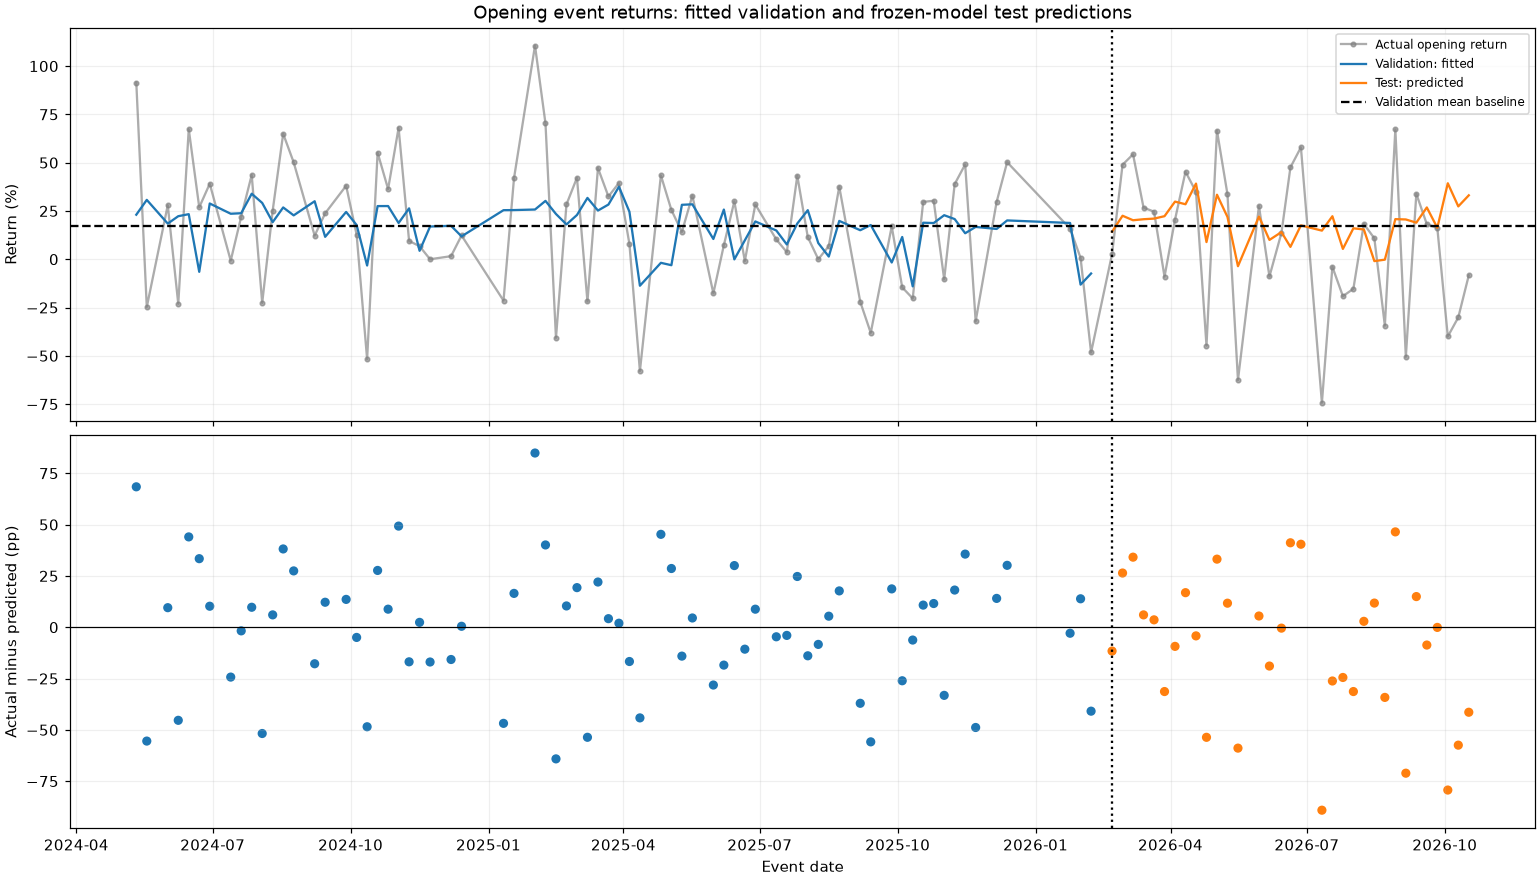

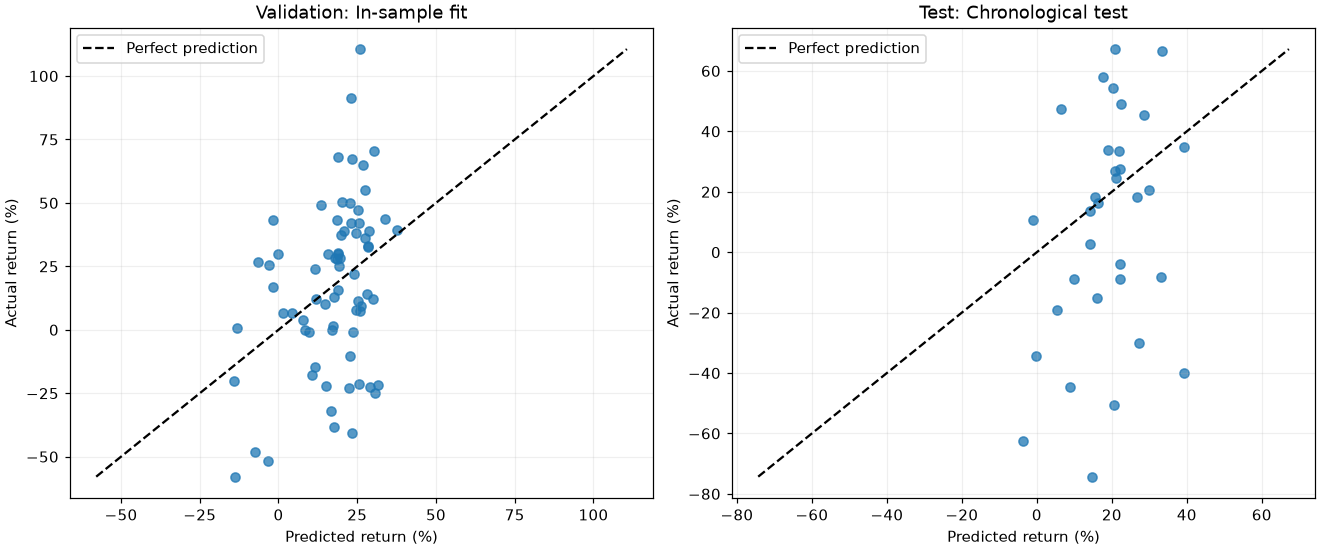

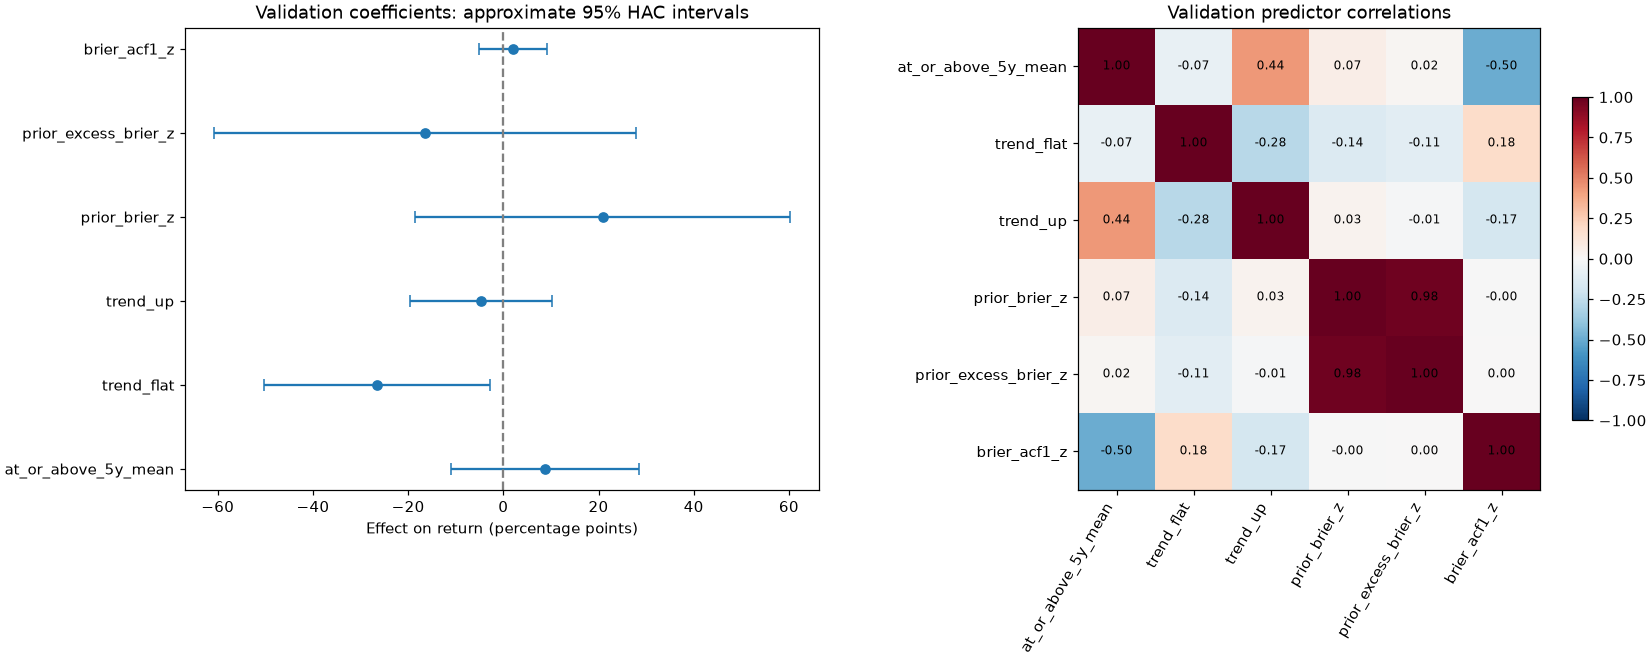

In [6]:
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
axes[0].plot(predictions.index,predictions.return_pct,color='gray',marker='.',alpha=.65,label='Actual opening return')
for split,color in [('Validation','tab:blue'),('Test','tab:orange')]:
    part=predictions.loc[predictions.split.eq(split)]
    axes[0].plot(part.index,part.prediction_pct,color=color,label=f'{split}: '+('fitted' if split=='Validation' else 'predicted'))
axes[0].axhline(validation.return_pct.mean(),color='black',ls='--',label='Validation mean baseline')
axes[0].set(title='Opening event returns: fitted validation and frozen-model test predictions',ylabel='Return (%)');axes[0].legend(fontsize=8)
axes[1].scatter(predictions.index,predictions.return_pct-predictions.prediction_pct,c=np.where(predictions.split.eq('Validation'),'tab:blue','tab:orange'),s=25)
axes[1].axhline(0,color='black',lw=.8);axes[1].set(ylabel='Actual minus predicted (pp)',xlabel='Event date')
for ax in axes:ax.axvline(test.index.min(),color='black',ls=':');ax.grid(alpha=.2)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,(split,part) in zip(axes,predictions.groupby('split',sort=False)):
    ax.scatter(part.prediction_pct,part.return_pct,alpha=.75)
    low=min(part.prediction_pct.min(),part.return_pct.min());high=max(part.prediction_pct.max(),part.return_pct.max())
    ax.plot([low,high],[low,high],'k--',label='Perfect prediction')
    ax.set(title=f'{split}: {part.evaluation.iloc[0]}',xlabel='Predicted return (%)',ylabel='Actual return (%)')
    ax.legend();ax.grid(alpha=.2)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
effects=coefficients.drop(index='const');positions=np.arange(len(effects))
axes[0].errorbar(effects.coefficient_pp,positions,
    xerr=np.vstack([effects.coefficient_pp-effects.CI95_low,effects.CI95_high-effects.coefficient_pp]),fmt='o',capsize=4)
axes[0].set_yticks(positions,effects.index);axes[0].axvline(0,color='gray',ls='--')
axes[0].set(title='Validation coefficients: approximate 95% HAC intervals',xlabel='Effect on return (percentage points)')
corr=X_validation.drop(columns='const').corr()
mesh=axes[1].imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
axes[1].set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right');axes[1].set_yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):axes[1].text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
axes[1].set_title('Validation predictor correlations');fig.colorbar(mesh,ax=axes[1],shrink=.7)
plt.show()


## All-event descriptive refit

Fit the same specification to all available events to summarize historical associations. Continuous scaling remains the validation scale for comparability. **This is an in-sample descriptive refit, not a second test or the source of the test predictions above.** Its HAC intervals treat the combined event sequence as one series and are approximate across the underlying model refit.


In [7]:
X_all=design(data)
full_fit=sm.OLS(data.return_pct,X_all).fit(cov_type='HAC',cov_kwds={'maxlags':HAC_LAGS,'use_correction':True},use_t=True)
full_ci=full_fit.conf_int()
full_coefficients=pd.DataFrame({'coefficient_pp':full_fit.params,'HAC_std_error':full_fit.bse,
    'CI95_low':full_ci[0],'CI95_high':full_ci[1],'p_value':full_fit.pvalues})
print('ALL-EVENT DESCRIPTIVE REFIT — NOT OUT-OF-SAMPLE')
print(full_coefficients.round(5).to_string())
print(f'Events={len(data)}; in-sample R-squared={full_fit.rsquared:.4f}; adjusted R-squared={full_fit.rsquared_adj:.4f}')


ALL-EVENT DESCRIPTIVE REFIT — NOT OUT-OF-SAMPLE
                      coefficient_pp  HAC_std_error  CI95_low  CI95_high  p_value
const                       19.85445        5.32480   9.28756   30.42133  0.00032
at_or_above_5y_mean          1.38590        7.98532 -14.46070   17.23251  0.86257
trend_flat                 -31.80341       11.55227 -54.72851   -8.87831  0.00704
trend_up                    -0.92433        6.69748 -14.21526   12.36659  0.89051
prior_brier_z               15.65360       14.66920 -13.45695   44.76415  0.28855
prior_excess_brier_z       -10.25879       16.51451 -43.03129   22.51372  0.53591
brier_acf1_z                -1.43747        2.07005  -5.54543    2.67048  0.48907
Events=105; in-sample R-squared=0.1425; adjusted R-squared=0.0900
